## PCA

In [1]:
import numpy as np
import pandas as pd

In [2]:
np.random.seed(23)

mu_vec1 = np.array([0, 0 ,0])
cov_mat1 = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1]])
class1_sample = np.random.multivariate_normal(mu_vec1, cov_mat1, 20)

In [3]:
df = pd.DataFrame(class1_sample, columns=['dim1','dim2','dim3'])
df['target'] = 1

In [9]:
mu_vec2 = np.array([1,1,1])
cov_mat2 = np.array([[1,0,0],[0,1,0],[0,0,1]])
class2_sample = np.random.multivariate_normal(mu_vec2, cov_mat2, 20)

df1 = pd.DataFrame(class2_sample, columns=['dim1','dim2','dim3'])
df1['target'] = 0

df = pd.concat([df, df1], ignore_index=True)

df = df.sample(40)

In [10]:
df.head()

,dim1,dim2,dim3,target
35,0.904913,-0.155969,0.183063,0
24,-0.310621,-0.182088,2.481469,0
10,1.415320,0.457711,0.728876,1
34,-0.561595,3.092138,1.311076,0
19,-0.992574,-0.161346,1.192404,1


In [13]:
import plotly.express as px

fig = px.scatter_3d(df, x=df['dim1'], y=df['dim2'], z=df['dim3'], color=df['target'].astype(str), title='3D Scatter Plot of Two Classes')
fig.update_traces(marker=dict(size=12, line=dict(width=2, color='DarkSlateGrey')), selector=dict(mode='markers'))

fig.show()

In [14]:
# step1 Apply standard scaling

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

df.iloc[:, 0:3] = scaler.fit_transform(df.iloc[:, 0:3])

In [15]:
#step-2 find covariance matrix
covariance_matrix = np.cov([df.iloc[:, 0], df.iloc[:, 1],df.iloc[:,2]])
print("Covariance Matrix:\n", covariance_matrix)



Covariance Matrix:
 [[ 1.02564103  0.20791798 -0.05314684]
 [ 0.20791798  1.02564103  0.36775644]
 [-0.05314684  0.36775644  1.02564103]]


In [17]:
#step-2 finding eigen values and eigen vectors 

eigen_values, eigen_vectors = np.linalg.eig(covariance_matrix)

In [18]:
eigen_values

array([0.57899131, 1.07098473, 1.42694704])

In [20]:
eigen_vectors

array([[ 0.39244093, -0.87207153,  0.29237196],
       [-0.68660087, -0.06624453,  0.7240103 ],
       [ 0.61202072,  0.48487411,  0.62476214]])

In [21]:
pc = eigen_vectors[0:2]
pc

array([[ 0.39244093, -0.87207153,  0.29237196],
       [-0.68660087, -0.06624453,  0.7240103 ]])

In [22]:
transformed_df = np.dot(df.iloc[:, 0:3], pc.T)

new_df = pd.DataFrame(transformed_df, columns=['PC1','PC2'])
new_df['target'] = df['target'].values

In [23]:
new_df.head()

,PC1,PC2,target
0,0.600242,-0.434602,0
1,0.842033,1.987037,0
2,0.411928,-0.411296,1
3,-2.427946,1.095243,0
4,0.202763,1.500395,1


## MNIST DATASET

In [24]:
df = pd.read_csv('/home/lucky/Machine_Learning/datasets/MINST_training_set.csv')

In [25]:
df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [26]:
df.shape

(42000, 785)

In [32]:
df.sample(5)

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
8797,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
22172,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5358,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
465,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
39410,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [28]:
import matplotlib.pyplot as plt


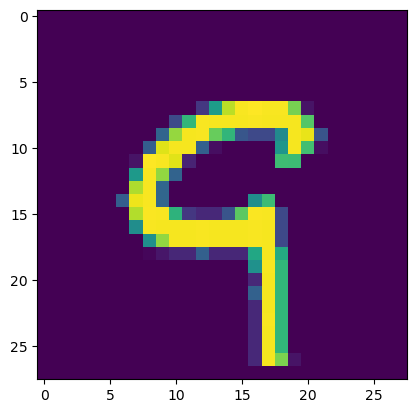

In [34]:
plt.imshow(df.iloc[39410, 1:].values.reshape(28,28))

In [35]:
X = df.iloc[:, 1:]
y = df.iloc[:, 0]

In [36]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)


In [37]:
X_train.shape

(33600, 784)

In [38]:
X_test.shape

(8400, 784)

In [39]:
from sklearn.neighbors import KNeighborsClassifier


In [40]:
knn = KNeighborsClassifier()

In [41]:
knn.fit(X_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [42]:
import time
start = time.time()
y_pred = knn.predict(X_test)
print(time.time() - start)

38.9765989780426


In [43]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.9648809523809524

In [44]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [45]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [49]:
X_train.shape

(33600, 784)

In [53]:
# PCA
from sklearn.decomposition import PCA
pca = PCA(n_components=100)

In [54]:
X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)

In [55]:
X_train_trf.shape

(33600, 100)

In [56]:
knn.fit(X_train_trf, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [57]:
y_pred = knn.predict(X_test_trf)

In [58]:
accuracy_score(y_test, y_pred)

0.9544047619047619

In [62]:
for i in range(1, 785):
    pca = PCA(n_components=i)
    X_train_trf = pca.fit_transform(X_train)
    X_test_trf = pca.transform(X_test)

    knn = KNeighborsClassifier()
    
    knn.fit(X_train_trf, y_train)

    y_pred = knn.predict(X_test_trf)

    print(accuracy_score(y_test, y_pred))

0.2580952380952381
0.3236904761904762


KeyboardInterrupt: 

In [63]:
# transferring to a 2D coordinate system

In [64]:
pca = PCA(n_components=2)
X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)

In [65]:
X_train_trf

array([[-2.71863253, -0.48982409],
       [-0.67698015, -6.75362491],
       [-3.03323281,  6.50981624],
       ...,
       [ 2.14883643,  0.78079444],
       [ 1.05957006,  0.94767312],
       [17.70258446,  1.96188185]], shape=(33600, 2))

In [66]:
import plotly.express as px
y_train_trf = y_train.astype(str)
fig = px.scatter(x=X_train_trf[:, 0],
                 y=X_train_trf[:, 1],
                 color=y_train_trf,
                 color_discrete_sequence=px.colors.qualitative.G10
                 )

fig.show()

In [67]:
# transforming in 3d


In [68]:
pca = PCA(n_components=3)
X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)

In [69]:
X_train_trf

array([[-2.71863253, -0.48982409,  1.1354966 ],
       [-0.67698015, -6.75362491, -2.33590139],
       [-3.03323281,  6.50981624,  7.49182983],
       ...,
       [ 2.14883643,  0.78079444, -0.74738774],
       [ 1.05957006,  0.94767312,  3.94973114],
       [17.70258446,  1.96188185, -4.94352837]], shape=(33600, 3))

In [70]:
y_train_trf = y_train.astype(str)
fig = px.scatter_3d(df, x=X_train_trf[:,0], y=X_train_trf[:, 1], z=X_train_trf[:,2], color=y_train_trf)

fig.update_layout(
    margin=dict(l=20, r=20, t=20, b=20)
)

fig.show()